# Учебное исследование территории: Покровское

**Курс «Технологии искусственного интеллекта в урбанистике»**

Ноутбук повторяет шаги официального примера
[pipeline.ipynb](https://github.com/aimclub/blocksnet/blob/main/examples/pipeline.ipynb)
библиотеки **BlocksNet** (версия 1.0.0a9), но для села **Покровское** (Неклиновский район, Ростовская область, Россия).

Порядок работы:
1. граница населённого пункта + данные OpenStreetMap;
2. нарезка территории на **кварталы**;
3. **время в пути** между кварталами (пешком и на машине);
4. данные о **зданиях** (население) и **сервисах**;
5. **показатели**: land use, плотность, морфотипы, обеспеченность, доступность.

Все результаты сохраняются в папку `data/pokrovskoe/` и переиспользуются при повторном запуске.

## Как запускать ноутбук

- Запускайте ячейки **по порядку сверху вниз** (`Shift+Enter` или кнопка ▶ слева от ячейки).
- Работайте в окружении проекта **`.venv`**: в правом верхнем углу выберите интерпретатор `.venv`.
- Данные скачиваются из интернета (**OpenStreetMap**), поэтому первый запуск может идти несколько минут.
- В разделе «**ОСТАНОВКА**» мы намеренно прерываемся: сначала вы выбираете показатели, потом продолжаем.
- Файлы результатов появятся в `data/pokrovskoe/` рядом с этим ноутбуком.
- Если нужно пересчитать всё с нуля — удалите папку `data/pokrovskoe/` и запустите заново.

## Шаг 0. Импорты и настройки

Здесь мы подключаем библиотеки, задаём папку для данных и адрес территории.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import osmnx as ox

import blocksnet
from blocksnet.config import service_types_config

# --- Куда складывать данные и результаты ---
DATA_DIR = Path("data") / "pokrovskoe"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# --- Территория исследования ---
TERRITORY = "Покровское, Неклиновский район, Ростовская область, Россия"

# --- Настройки OpenStreetMap (кэш ускоряет повторные запуски) ---
ox.settings.use_cache = True
ox.settings.cache_folder = str(DATA_DIR / "osm_cache")
ox.settings.log_console = False
# Overpass бывает перегружен: даём больше времени и используем рабочий сервер
ox.settings.requests_timeout = 900
ox.settings.overpass_url = "https://overpass-api.de/api"

print("blocksnet:", blocksnet.__version__)
print("geopandas:", gpd.__version__)
print("osmnx:", ox.__version__)
print("pandas:", pd.__version__)
print("Папка данных:", DATA_DIR.resolve())

blocksnet: 1.0.0a9
geopandas: 1.2.0
osmnx: 2.1.1
pandas: 2.3.3
Папка данных: C:\Users\olesy\Рабочий стол\agents practice\python-package-boilerplate\examples\data\pokrovskoe


## Шаг 0.1. Помощник кэширования

Чтобы не скачивать и не считать одно и то же каждый раз, все результаты сохраняются в файлы.
Функция `cached` работает так: **есть файл — читаю его, нет файла — считаю и сохраняю.**

In [2]:
def cached(name, builder, kind="geojson"):
    '''Возвращает результат, сохраняя его в файл (geojson / csv / pkl).

    name    -- имя файла без расширения;
    builder -- функция без аргументов, которая считает результат;
    kind    -- тип файла: 'geojson' для слоёв, 'csv' для таблиц, 'pkl' для графа.
    '''
    if kind == "geojson":
        path = DATA_DIR / f"{name}.geojson"
        if path.exists():
            print(f"[кэш] читаю {path.name}")
            return gpd.read_file(path)
        obj = builder()
        obj.to_file(path, driver="GeoJSON")
    elif kind == "csv":
        path = DATA_DIR / f"{name}.csv"
        if path.exists():
            print(f"[кэш] читаю {path.name}")
            return pd.read_csv(path, index_col=0)
        obj = builder()
        obj.to_csv(path)
    elif kind == "pkl":
        import pickle
        path = DATA_DIR / f"{name}.pkl"
        if path.exists():
            print(f"[кэш] читаю {path.name}")
            with open(path, "rb") as f:
                return pickle.load(f)
        obj = builder()
        with open(path, "wb") as f:
            pickle.dump(obj, f)
    else:
        raise ValueError("kind должен быть geojson, csv или pkl")
    print(f"[сохранил] {path.name}")
    return obj

## Шаг 1. Граница территории

`ox.geocode_to_gdf` обращается к сервису **Nominatim** (поиск по названию в OpenStreetMap)
и возвращает границу населённого пункта. Затем мы переводим координаты в **метрическую систему (UTM)** —
в метрах удобно считать площади и расстояния.

[кэш] читаю boundary.geojson
CRS (система координат): EPSG:32637
Площадь границы, га: 1406.0


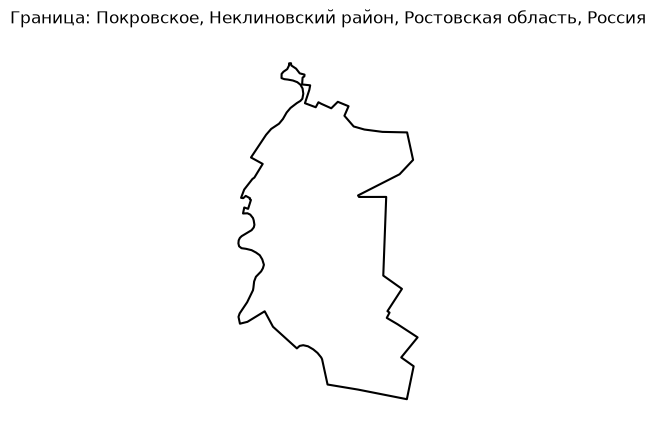

In [3]:
def build_boundary():
    gdf = ox.geocode_to_gdf(TERRITORY)          # граница из OpenStreetMap
    gdf = gdf[["geometry"]].copy()              # оставляем только геометрию
    return gdf.to_crs(gdf.estimate_utm_crs())   # перевод в метры (UTM)

boundary = cached("boundary", build_boundary)

print("CRS (система координат):", boundary.crs.to_string())
print("Площадь границы, га:", round(boundary.area.sum() / 10_000, 1))

boundary.plot(color="none", edgecolor="black", linewidth=1.5).set_axis_off()
plt.title(f"Граница: {TERRITORY}");

## Шаг 2. Данные OpenStreetMap (дороги, железные дороги, вода)

Для нарезки кварталов нужны **линейные барьеры** (дороги, ж/д) и **вода** (реки, каналы, озёра).
Тег-фильтры `BC_TAGS` взяты из официального примера `pipeline.ipynb`.

Внимание: в небольшом селе каких-то объектов может не быть — тогда слой просто будет пустым.

In [4]:
BC_TAGS = {
    "roads": {
        "highway": ["construction", "crossing", "living_street", "motorway", "motorway_link",
                    "motorway_junction", "pedestrian", "primary", "primary_link", "raceway",
                    "residential", "road", "secondary", "secondary_link", "services", "tertiary",
                    "tertiary_link", "track", "trunk", "trunk_link", "turning_circle",
                    "turning_loop", "unclassified"],
        "service": ["living_street", "emergency_access"],
    },
    "railways": {"railway": "rail"},
    "water": {
        "riverbank": True, "reservoir": True, "basin": True, "dock": True, "canal": True,
        "pond": True, "natural": ["water", "bay"], "waterway": ["river", "canal", "ditch"],
        "landuse": "basin", "water": "lake",
    },
}

def fetch_osm(tags):
    '''Берёт объекты OSM из заранее скачанного файла osm_all.pkl и фильтрует по тегам.

    Все нужные объекты OSM скачиваются один раз и лежат в osm_all.pkl.
    Это быстрее и надёжнее, чем отдельный запрос к Overpass на каждый слой.
    '''
    osm_all = DATA_DIR / "osm_all.pkl"
    if not osm_all.exists():
        raise FileNotFoundError(
            f"Нет файла {osm_all}. Сначала скачайте данные OSM в osm_all.pkl."
        )
    gdf = pd.read_pickle(osm_all)
    if gdf.crs is None:
        gdf = gdf.set_crs(4326)

    polygon = boundary.to_crs(4326).union_all()

    mask = pd.Series(False, index=gdf.index)
    for key, values in tags.items():
        if key not in gdf.columns:
            continue
        if values is True:
            mask |= gdf[key].notna()
        elif isinstance(values, str):
            mask |= gdf[key] == values
        elif isinstance(values, list):
            mask |= gdf[key].isin(values)

    gdf = gdf[mask]
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty]
    gdf = gdf[gdf.geometry.intersects(polygon)]
    if gdf.empty:
        print("Нет данных OSM для", tags)
        return gpd.GeoDataFrame(geometry=[], crs=boundary.crs)
    return gdf.to_crs(boundary.crs).dropna(axis="columns", how="all")

def build_roads():
    gdf = fetch_osm(BC_TAGS["roads"])
    return gdf[gdf.geom_type.isin(["LineString", "MultiLineString"])].copy()

def build_railways():
    gdf = fetch_osm(BC_TAGS["railways"])
    return gdf[gdf.geom_type.isin(["LineString", "MultiLineString"])].copy()

def build_water():
    gdf = fetch_osm(BC_TAGS["water"])
    return gdf[gdf.geom_type.isin(["Polygon", "MultiPolygon", "LineString", "MultiLineString"])].copy()

roads = cached("roads", build_roads)
railways = cached("railways", build_railways)
water = cached("water", build_water)

print("дороги:", len(roads), "| ж/д:", len(railways), "| вода:", len(water))

[кэш] читаю roads.geojson
[кэш] читаю railways.geojson
[кэш] читаю water.geojson
дороги: 213 | ж/д: 17 | вода: 2


## Шаг 3. Нарезка кварталов

Квартал — это территория, ограниченная дорогами, железными дорогами и водой.
Две функции делают всю работу:
- `preprocess_urban_objects` — приводит объекты к единому виду;
- `cut_urban_blocks` — «разрезает» территорию на кварталы.

[кэш] читаю blocks.geojson
Кварталов: 143


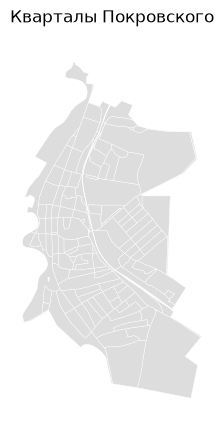

In [5]:
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks

def build_blocks():
    lines, polygons = preprocess_urban_objects(roads, railways, water)
    blocks = cut_urban_blocks(boundary, lines, polygons)
    return blocks.reset_index(drop=True)   # ровный индекс 0,1,2,... — важно для расчётов

blocks = cached("blocks", build_blocks)

print("Кварталов:", len(blocks))
blocks.plot(color="#dddddd", edgecolor="white", linewidth=0.3).set_axis_off()
plt.title("Кварталы Покровского");

In [6]:
# Размеры кварталов — простая проверка, что нарезка разумная
blocks["area_ha"] = blocks.area / 10_000
print("Кварталов:", len(blocks))
print("Площадь квартала, га:")
print(blocks["area_ha"].describe().round(2))

Кварталов: 143
Площадь квартала, га:
count    143.00
mean       9.83
std       19.36
min        0.01
25%        2.38
50%        5.13
75%        8.63
max      144.35
Name: area_ha, dtype: float64


---
# ⛔ ОСТАНОВКА: выберите показатели

Кварталы готовы и сохранены в `data/pokrovskoe/blocks.geojson`.
Дальше идут расчёты — **прежде чем их запускать, определитесь с метриками**.

### Что доступно в BlocksNet 1.0.0a9 (категории)

| Категория | Что показывает | Где в библиотеке |
|---|---|---|
| **Плотность застройки** | FSI, GSI, MXI, этажность, озеленённость | `blocksnet.analysis.indicators.density` |
| **Развитие территории** | показатели застройки и населения | `blocksnet.analysis.indicators.development` |
| **Морфотипы** | типы городской среды (Spacematrix, Strelka) | `blocksnet.analysis.morphotypes` |
| **Обеспеченность сервисами** | конкурентная доступность школ, садиков, аптек и т.д. | `blocksnet.analysis.provision` |
| **Доступность** | среднее/медианное время, доступность по площади и land use | `blocksnet.analysis.network.accessibility` |
| **Связность сети** | связность улично-дорожной сети | `blocksnet.analysis.network.connectivity` |
| **Центральность** | центральность по населению и сервисам | `blocksnet.analysis.centrality` |
| **Land use** | состав, сочетаемость, разнообразие функций | `blocksnet.analysis.land_use` |
| **Разнообразие** | индекс Шеннона | `blocksnet.analysis.diversity.shannon` |
| **Социально-экономические** | демография, экономика, транспорт, экология | `blocksnet.analysis.indicators.socio_economic` |

**Сейчас в ноутбуке по умолчанию считаются показатели из `pipeline.ipynb`:**
land use, время в пути, население, обеспеченность сервисами, плотность, морфотипы, доступность.

👉 **Скажите, какие метрики вам нужны.** Пока это не сделано — просто не запускайте ячейки ниже.
Если набор по умолчанию вас устраивает, продолжайте запускать ячейки подряд.

## Настройки расчётов

Здесь задаются параметры для следующих шагов. Меняйте под свою задачу:

- `SERVICE_TAGS` — какие сервисы считать (тип BlocksNet → как искать в OSM);
- `LAND_USE_RULES` — как переводить функциональные зоны OSM в категории land use;
- `MORPHOTYPE_N_CLUSTERS` — число морфотипов (для небольшого села хватает 4–8).

In [7]:
# какие сервисы считаем: "тип в BlocksNet": {"как искать в OSM"}
SERVICE_TAGS = {
    "school":       {"amenity": "school"},
    "kindergarten": {"amenity": "kindergarten"},
    "hospital":     {"amenity": "hospital"},
    "polyclinic":   {"amenity": "clinic"},
    "pharmacy":     {"amenity": "pharmacy"},
    "supermarket":  {"shop": "supermarket"},
    "convenience":  {"shop": "convenience"},
    "cafe":         {"amenity": "cafe"},
    "restaurant":   {"amenity": "restaurant"},
    "bank":         {"amenity": "bank"},
    "post":         {"amenity": "post_office"},
    "police":       {"amenity": "police"},
    "playground":   {"leisure": "playground"},
    "park":         {"leisure": "park"},
    "bus_stop":     {"highway": "bus_stop"},
    "market":       {"amenity": "marketplace"},
    "library":      {"amenity": "library"},
    "museum":       {"tourism": "museum"},
}

# правила: функциональная зона OSM -> категория land use у BlocksNet
from blocksnet.enums import LandUse

LAND_USE_RULES = {
    "commercial": LandUse.BUSINESS,
    "industrial": LandUse.INDUSTRIAL,
    "cemetery": LandUse.SPECIAL,
    "garages": LandUse.INDUSTRIAL,
    "residential": LandUse.RESIDENTIAL,
    "retail": LandUse.BUSINESS,
    "grass": LandUse.RECREATION,
    "farmland": LandUse.AGRICULTURE,
    "construction": LandUse.SPECIAL,
    "brownfield": LandUse.INDUSTRIAL,
    "forest": LandUse.RECREATION,
    "recreation_ground": LandUse.RECREATION,
    "religious": LandUse.SPECIAL,
    "flowerbed": LandUse.RECREATION,
    "military": LandUse.SPECIAL,
    "landfill": LandUse.TRANSPORT,
}

MORPHOTYPE_N_CLUSTERS = 6   # для Покровского достаточно небольшого числа типов

print("Сервисов в расчёте:", len(SERVICE_TAGS))

Сервисов в расчёте: 18


## Шаг 4. Функциональное использование территории (land use)

Берём из OSM зоны `landuse` (жилые, коммерческие, промышленные и т.д.) и по правилам
`LAND_USE_RULES` присваиваем каждому кварталу преобладающую функцию.

[кэш] читаю functional_zones.geojson
Функциональных зон из OSM: 27
[кэш] читаю blocks_land_use.geojson
Кварталов с назначенным land use: 143 из 143


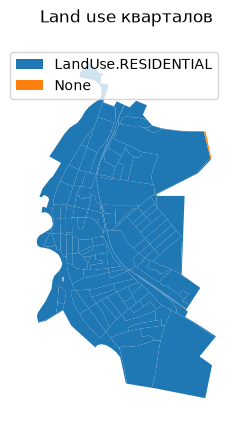

In [8]:
from blocksnet.blocks.assignment import assign_land_use

def build_functional_zones():
    gdf = fetch_osm({"landuse": True})
    if gdf.empty:
        return gdf
    gdf = gdf.reset_index(drop=True)
    keep = [c for c in ["geometry", "landuse"] if c in gdf.columns]
    gdf = gdf[keep].rename(columns={"landuse": "functional_zone"})
    if "functional_zone" not in gdf.columns:
        return gpd.GeoDataFrame(geometry=[], crs=boundary.crs)
    return gdf

functional_zones = cached("functional_zones", build_functional_zones)
print("Функциональных зон из OSM:", len(functional_zones))

if len(functional_zones) == 0:
    print("В OSM нет данных landuse — пропускаю назначение функций")
    blocks_land_use = blocks.copy()
    blocks_land_use["land_use"] = None
else:
    def build_land_use():
        result = assign_land_use(blocks, functional_zones, LAND_USE_RULES)
        result["land_use"] = result["land_use"].astype(str)   # строкой — чтобы сохранилось в GeoJSON
        return result

    blocks_land_use = cached("blocks_land_use", build_land_use)

block_land_use = blocks.join(blocks_land_use[["land_use"]])
print("Кварталов с назначенным land use:", block_land_use["land_use"].notna().sum(), "из", len(block_land_use))
block_land_use.plot(column="land_use", legend=True, cmap="tab10", missing_kwds={"color": "#eeeeee"}).set_axis_off()
plt.title("Land use кварталов");

## Шаг 5. Граф улично-дорожной сети

Для расчёта времени в пути нужен **граф дорог**. Мы берём **готовые графы из OpenStreetMap**
(через библиотеку IduEdu) в двух режимах:

- **`walk`** — пешеходный, скорость по умолчанию 5 км/ч;
- **`drive`** — автомобильный.

Интермодальный граф (с общественным транспортом) **не строим** — для небольшого села он избыточен.
У каждого ребра графа есть вес **`time_min`** — время проезда/прохода в **минутах**.
Источник данных: **OpenStreetMap**. Графы сохраняются в `graph_walk.pkl` и `graph_drive.pkl`
и переиспользуются при повторном запуске.

In [9]:
from blocksnet.relations import get_accessibility_graph

graph_walk = cached("graph_walk", lambda: get_accessibility_graph(boundary, "walk"), kind="pkl")
graph_drive = cached("graph_drive", lambda: get_accessibility_graph(boundary, "drive"), kind="pkl")

print("Пеший граф:  узлов", graph_walk.number_of_nodes(), "| рёбер", graph_walk.number_of_edges())
print("Авто граф:   узлов", graph_drive.number_of_nodes(), "| рёбер", graph_drive.number_of_edges())

[кэш] читаю graph_walk.pkl
[кэш] читаю graph_drive.pkl
Пеший граф:  узлов 542 | рёбер 1496
Авто граф:   узлов 292 | рёбер 763


## Шаг 6. Матрицы времени между кварталами (минуты)

`calculate_accessibility_matrix` считает время от центра каждого квартала до центра каждого другого.
Получается таблица «квартал → квартал», где значения — **минуты** (по графу из шага 5).

Мы считаем **две** матрицы: пешком и на автомобиле.

In [10]:
from blocksnet.relations import calculate_accessibility_matrix

def load_acc_matrix(name, graph):
    '''Считает или читает матрицу времени и приводит индекс/столбцы к целым числам.'''
    path = DATA_DIR / f"{name}.csv"
    if path.exists():
        print(f"[кэш] читаю {path.name}")
        mx = pd.read_csv(path, index_col=0)
    else:
        mx = calculate_accessibility_matrix(blocks, graph)
        mx.to_csv(path)
        print(f"[сохранил] {path.name}")
    mx.index = mx.index.astype(int)      # после чтения CSV индексы становятся строками —
    mx.columns = mx.columns.astype(int)  # возвращаем целые числа
    return mx

acc_walk = load_acc_matrix("acc_walk", graph_walk)
acc_drive = load_acc_matrix("acc_drive", graph_drive)

print("Размер пешей матрицы:", acc_walk.shape)
print("Среднее время пешком между кварталами, мин:", round(acc_walk.values.mean(), 1))
print("Среднее время на авто между кварталами, мин:", round(acc_drive.values.mean(), 1))
acc_walk.iloc[:5, :5].round(1)

[кэш] читаю acc_walk.csv
[кэш] читаю acc_drive.csv
Размер пешей матрицы: (143, 143)
Среднее время пешком между кварталами, мин: 29.5
Среднее время на авто между кварталами, мин: 6.1


,0,1,2,3,4
0,0.0,27.4,26.2,9.9,23.8
1,27.4,0.0,29.4,37.0,34.8
2,26.2,29.4,0.0,22.7,21.4
3,9.9,37.0,22.7,0.0,20.3
4,23.8,34.8,21.4,20.3,0.0


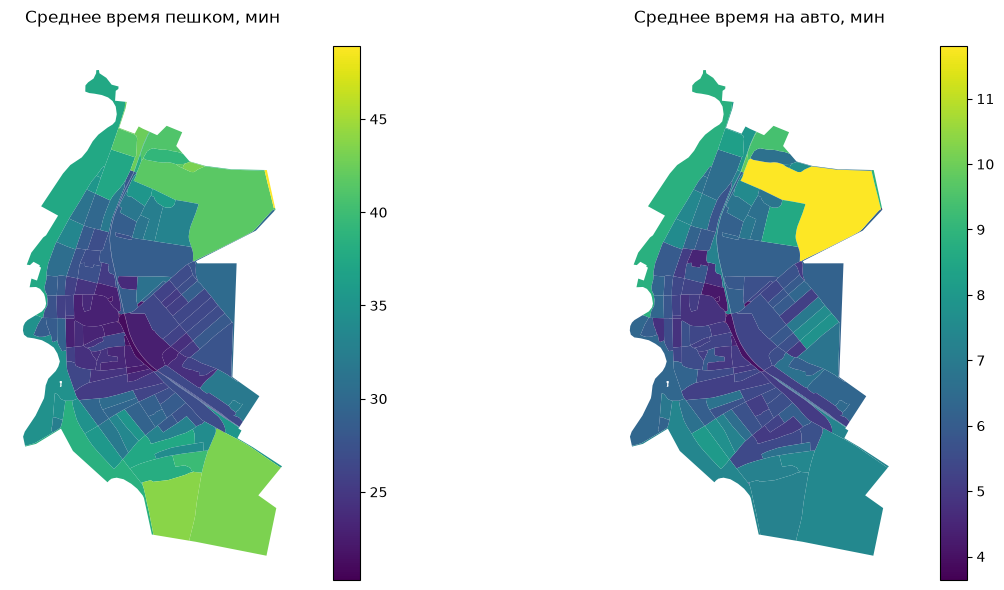

In [11]:
# Карта «насколько квартал хорошо связан»: среднее время до всех остальных
def block_mean_time(mx):
    m = mx.mean(axis=1)
    m.index = m.index.astype(int)
    return m.reindex(blocks.index).values

blocks_time = blocks.copy()
blocks_time["время_пешком_мин"] = block_mean_time(acc_walk)
blocks_time["время_авто_мин"] = block_mean_time(acc_drive)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
blocks_time.plot("время_пешком_мин", legend=True, ax=axes[0], cmap="viridis").set_axis_off()
axes[0].set_title("Среднее время пешком, мин")
blocks_time.plot("время_авто_мин", legend=True, ax=axes[1], cmap="viridis").set_axis_off()
axes[1].set_title("Среднее время на авто, мин")
plt.tight_layout();

## Шаг 7. Здания и население

Берём здания из OSM, определяем жилые (`is_living`), берём этажность (`building:levels`).
Где данных не хватает, `impute_buildings` **додумывает** их по разумным правилам
(например, 1 этаж, если не указано) и оценивает **население**.

In [12]:
from blocksnet.preprocessing.imputing import impute_buildings

def build_buildings():
    gdf = fetch_osm({"building": True})
    if gdf.empty:
        raise ValueError("В OSM нет зданий")
    gdf = gdf.reset_index(drop=True)

    is_living_tags = ["residential", "house", "apartments", "detached", "terrace", "dormitory"]
    gdf["is_living"] = gdf["building"].apply(lambda b: b in is_living_tags)

    if "building:levels" in gdf.columns:
        gdf["number_of_floors"] = pd.to_numeric(gdf["building:levels"], errors="coerce")
    else:
        gdf["number_of_floors"] = np.nan

    return impute_buildings(gdf, default_living_demand=30)

buildings = cached("buildings", build_buildings)
print("Зданий:", len(buildings))
print("Оценочное население села, чел.:", int(buildings["population"].sum()))
buildings.head(3)

[кэш] читаю buildings.geojson
Зданий: 3434
Оценочное население села, чел.: 3765


,is_living,number_of_floors,footprint_area,build_floor_area,living_area,non_living_area,population,geometry
0,False,2.0,1288.007215,2576.014430,0.0,2576.014430,NaN,"POLYGON ((492195.136 5251277.297, 492239.667 5..."
1,False,1.0,804.690747,804.690747,0.0,804.690747,NaN,"POLYGON ((492207.056 5251346.896, 492146.216 5..."
2,False,1.0,1104.517780,1104.517780,0.0,1104.517780,NaN,"POLYGON ((492090.492 5251433.971, 492115.567 5..."


[кэш] читаю blocks_buildings.geojson
Кварталов: 143


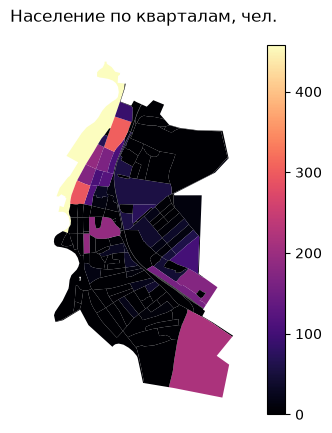

In [13]:
from blocksnet.blocks.aggregation import aggregate_objects

def build_blocks_buildings():
    agg = aggregate_objects(blocks, buildings)[0]   # [0] — кварталы с данными зданий
    agg["site_area"] = agg.area                     # площадь квартала — нужна для показателей
    return agg

blocks_buildings = cached("blocks_buildings", build_blocks_buildings)
print("Кварталов:", len(blocks_buildings))
blocks_buildings.plot("population", legend=True, cmap="magma").set_axis_off()
plt.title("Население по кварталам, чел.");

## Шаг 8. Сервисы

Для каждого типа сервиса из `SERVICE_TAGS` скачиваем объекты из OSM, оцениваем вместимость
(`impute_services`) и складываем по кварталам. Если какого-то сервиса в селе нет —
шаг просто пропускается.

In [14]:
from blocksnet.preprocessing.imputing import impute_services

def build_services_blocks(service_type):
    gdf = fetch_osm(SERVICE_TAGS[service_type])
    if gdf.empty:
        raise ValueError("нет объектов OSM")
    gdf = gdf.reset_index(drop=True)
    gdf = impute_services(gdf, service_type)
    agg = aggregate_objects(blocks, gdf)[0]
    return agg[[agg.geometry.name, "capacity", "count"]]

services_blocks = {}
for st in SERVICE_TAGS:
    try:
        services_blocks[st] = cached(f"services_{st}", lambda st=st: build_services_blocks(st))
        n = int(services_blocks[st]["count"].sum())
        print(f"  {st}: объектов — {n}")
    except Exception as exc:
        print(f"  {st}: пропущено ({exc})")

print("Сервисов с данными:", len(services_blocks))

[кэш] читаю services_school.geojson
  school: объектов — 3
[кэш] читаю services_kindergarten.geojson
  kindergarten: объектов — 3
[кэш] читаю services_hospital.geojson
  hospital: объектов — 4
[кэш] читаю services_polyclinic.geojson
  polyclinic: объектов — 1
[кэш] читаю services_pharmacy.geojson
  pharmacy: объектов — 4
[кэш] читаю services_supermarket.geojson
  supermarket: объектов — 6
[кэш] читаю services_convenience.geojson


  convenience: объектов — 21
[кэш] читаю services_cafe.geojson
  cafe: объектов — 2
[кэш] читаю services_restaurant.geojson
  restaurant: объектов — 1
[кэш] читаю services_bank.geojson
  bank: объектов — 3
[кэш] читаю services_post.geojson
  post: объектов — 3
[кэш] читаю services_police.geojson
  police: объектов — 3


[кэш] читаю services_playground.geojson
  playground: объектов — 1
[кэш] читаю services_park.geojson
  park: объектов — 2
[кэш] читаю services_bus_stop.geojson
  bus_stop: объектов — 1
[кэш] читаю services_market.geojson
  market: объектов — 8
[кэш] читаю services_library.geojson
  library: объектов — 1


Нет данных OSM для {'tourism': 'museum'}
  museum: пропущено (нет объектов OSM)
Сервисов с данными: 17


## Шаг 9. Обеспеченность сервисами

`competitive_provision` отвечает на вопрос: **хватает ли жителям сервисов рядом?**
Он сравнивает спрос (население) и предложение (вместимость сервисов) с учётом времени в пути.
Для этого используются нормативы спроса и порога доступности из настроек BlocksNet.

Результат `provision_strong` — доля спроса, закрытая **в пределах нормативной доступности**
(от 0 до 1, где 1 — всё обеспечено).

In [15]:
from blocksnet.analysis.provision import competitive_provision

provision = {}
for st, sblocks in services_blocks.items():
    if "capacity" not in sblocks.columns:
        continue
    df = blocks_buildings[["population"]].join(sblocks[["capacity"]])
    cfg = service_types_config[st]
    prov_df, links_df = competitive_provision(df, acc_walk, cfg["accessibility"], cfg["demand"])
    layer = blocks.join(prov_df[["provision_strong", "provision_weak"]])
    layer.to_file(DATA_DIR / f"provision_{st}.geojson", driver="GeoJSON")
    provision[st] = layer
    print(f"  {st}: обеспеченность (пешком) = {prov_df['provision_strong'].mean():.2f}")

print("Посчитано для сервисов:", len(provision))

2026-10-22 14:57:06.479 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame


2026-10-22 14:57:06.479 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter


2026-10-22 14:57:06.494 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities


2026-10-22 14:57:06.504 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached


2026-10-22 14:57:06.573 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


...

2026-10-22 14:57:08.528 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities


2026-10-22 14:57:08.528 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached


  bus_stop: обеспеченность (пешком) = 0.04
  market: обеспеченность (пешком) = 1.00


2026-10-22 14:57:08.608 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


  library: обеспеченность (пешком) = 0.73
Посчитано для сервисов: 17


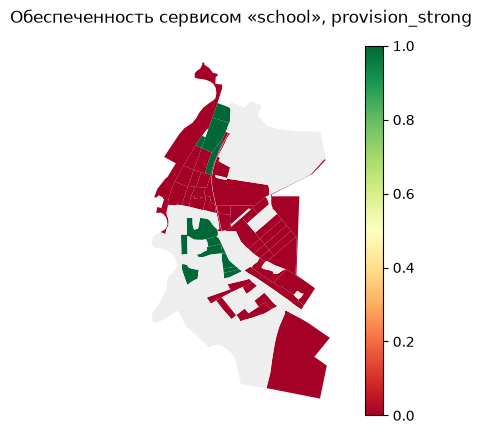

In [16]:
# Карта обеспеченности школами (или первым доступным сервисом)
if provision:
    st = "school" if "school" in provision else next(iter(provision))
    provision[st].plot("provision_strong", legend=True, cmap="RdYlGn",
                       vmin=0, vmax=1, missing_kwds={"color": "#eeeeee"}).set_axis_off()
    plt.title(f"Обеспеченность сервисом «{st}», provision_strong");
else:
    print("Нет данных для карты обеспеченности")

## Шаг 10. Плотность застройки и морфотипы

- **Плотность** (`calculate_density_indicators`): FSI, GSI, MXI, этажность и др.
- **Морфотипы**: `spacematrix` (по плотности и этажности) и `strelka` (типология городской среды).

In [17]:
from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes

density = calculate_density_indicators(blocks_buildings)
density_cols = ["fsi", "gsi", "mxi", "l", "osr", "share_living", "share_non_living"]
density[density_cols].describe().round(2)

,fsi,gsi,mxi,l,osr,share_living,share_non_living
count,143.00,143.00,107.00,107.00,143.00,107.00,107.00
mean,0.05,0.05,0.23,1.03,inf,0.24,0.79
std,0.05,0.05,0.34,0.12,NaN,0.36,0.35
min,0.00,0.00,0.00,1.00,3.98,0.00,0.10
25%,0.00,0.00,0.00,1.00,11.09,0.00,0.56
50%,0.03,0.02,0.00,1.00,35.26,0.00,1.00
75%,0.08,0.08,0.44,1.00,NaN,0.44,1.00
max,0.20,0.20,0.90,1.70,inf,1.52,1.70


Морфотипы Spacematrix:
morphotype
low-rise low-density non-residential    79
low-rise low-density residential        28
Name: count, dtype: int64


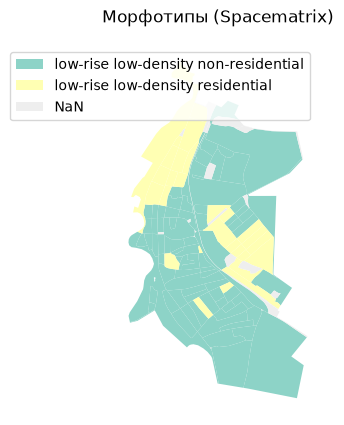

In [18]:
spacematrix, spacematrix_clusters = get_spacematrix_morphotypes(density, n_clusters=MORPHOTYPE_N_CLUSTERS)
strelka = get_strelka_morphotypes(density)

print("Морфотипы Spacematrix:")
print(spacematrix["morphotype"].value_counts())

blocks.join(spacematrix[["morphotype"]]).plot(
    column="morphotype", legend=True, cmap="Set3", missing_kwds={"color": "#eeeeee"}
).set_axis_off()
plt.title("Морфотипы (Spacematrix)");

## Шаг 11. Анализ доступности

`area_accessibility` показывает, сколько в среднем минут нужно от квартала до всей территории
(чем меньше — тем «центральнее» расположен квартал).

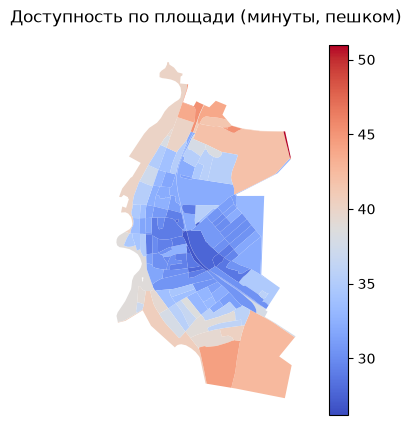

In [19]:
from blocksnet.analysis.network.accessibility import area_accessibility, relative_accessibility

area_acc = area_accessibility(acc_walk, blocks_buildings)
blocks.join(area_acc).plot("area_accessibility", legend=True, cmap="coolwarm").set_axis_off()
plt.title("Доступность по площади (минуты, пешком)");

## Шаг 12. Сводный слой и итоговая таблица

Собираем ключевые показатели в один слой `results_blocks.geojson` и краткую таблицу
`results_summary.csv`.

In [20]:
results = blocks.copy()
results["время_пешком_мин"] = block_mean_time(acc_walk)
results["время_авто_мин"] = block_mean_time(acc_drive)
results = results.join(blocks_buildings[["population"]])
results = results.join(density[density_cols])
results = results.join(spacematrix[["morphotype"]])
results = results.join(strelka[["morphotype"]].rename(columns={"morphotype": "morphotype_strelka"}))
results = results.join(area_acc)
results["land_use"] = block_land_use["land_use"].astype(str)

# pyogrio не умеет записывать float16 — приводим такие колонки к float64
for col in results.select_dtypes(include=["float16"]).columns:
    results[col] = results[col].astype("float64")

results.to_file(DATA_DIR / "results_blocks.geojson", driver="GeoJSON")
print("Сохранён слой результатов: results_blocks.geojson")

summary = pd.DataFrame(
    {
        "Кварталов": [len(blocks)],
        "Население (оценка), чел.": [int(blocks_buildings["population"].sum())],
        "Среднее время пешком, мин": [round(float(acc_walk.values.mean()), 1)],
        "Среднее время на авто, мин": [round(float(acc_drive.values.mean()), 1)],
        "Сервисов посчитано": [len(services_blocks)],
        "Средний FSI": [round(float(density["fsi"].mean()), 2)],
        "Средний GSI": [round(float(density["gsi"].mean()), 2)],
    }
).T
summary.columns = ["Значение"]
summary.to_csv(DATA_DIR / "results_summary.csv")
summary

Сохранён слой результатов: results_blocks.geojson


,Значение
Кварталов,143.00
"Население (оценка), чел.",3765.00
"Среднее время пешком, мин",29.50
"Среднее время на авто, мин",6.10
Сервисов посчитано,17.00
Средний FSI,0.05
Средний GSI,0.05


## Шаг 13. Проверка результатов

Небольшая проверка: совпадают ли системы координат, нет ли пустых геометрий и странных значений.

In [21]:
checks = []

# 1. Все слои в одной системе координат
for name, layer in [("boundary", boundary), ("blocks", blocks), ("blocks_buildings", blocks_buildings)]:
    checks.append((f"CRS {name} = {boundary.crs.to_epsg()}", layer.crs.to_epsg() == boundary.crs.to_epsg()))

# 2. Нет пустых геометрий в кварталах
checks.append(("Нет пустых геометрий", bool(blocks.geometry.is_valid.all())))

# 3. Кварталов больше нуля
checks.append(("Кварталов > 0", len(blocks) > 0))

# 4. Матрицы квадратные и индексы совпадают
checks.append(("Матрица walk квадратная", list(acc_walk.index) == list(acc_walk.columns)))
checks.append(("Матрица drive квадратная", list(acc_drive.index) == list(acc_drive.columns)))
checks.append(("Диагональ walk = 0", bool((pd.Series(acc_walk.values.diagonal()).abs() < 1e-6).all())))

# 5. Оценка населения правдоподобна (Покровское ~ 12 тыс. чел.)
pop = int(blocks_buildings["population"].sum())
checks.append(("Население в диапазоне 500..50000", 500 <= pop <= 50000))

for name, ok in checks:
    print(("OK   " if ok else "ПРОВЕРЬ") + " " + name)

all_ok = all(ok for _, ok in checks)
print()
print("ИТОГ:", "все проверки пройдены" if all_ok else "есть пункты для проверки вручную")

OK    CRS boundary = 32637
OK    CRS blocks = 32637
OK    CRS blocks_buildings = 32637
OK    Нет пустых геометрий
OK    Кварталов > 0
OK    Матрица walk квадратная
OK    Матрица drive квадратная
OK    Диагональ walk = 0
OK    Население в диапазоне 500..50000

ИТОГ: все проверки пройдены


## Как запускать повторно

**Обычный повторный запуск** (данные уже скачаны):

1. Откройте этот ноутбук.
2. Убедитесь, что выбран интерпретатор `.venv` (правый верхний угол).
3. Меню **«Run All»** (Запустить все) — или запускайте ячейки по порядку.
4. Ячейки с надписью `[кэш]` берут готовые файлы из `data/pokrovskoe/` и работают быстро.

**Если изменили территорию или хотите пересчитать заново:**

- удалите файл конкретного шага (например `data/pokrovskoe/blocks.geojson`) — он посчитается заново;
- либо удалите всю папку `data/pokrovskoe/` — тогда всё скачается и посчитается с нуля.

**Если удалили `osm_all.pkl`** (данные OSM), скачайте их заново из корня проекта:

```sh
python examples/download_osm_pokrovskoe.py
```

Скрипт сам перебирает серверы Overpass и сохраняет файл в `data/pokrovskoe/`.

**Что где лежит в `data/pokrovskoe/`:**

| Файл | Что это |
|---|---|
| `boundary.geojson` | граница населённого пункта |
| `osm_all.pkl` | все данные OSM, скачанные один раз |
| `roads/railways/water.geojson` | данные OSM |
| `blocks.geojson` | кварталы |
| `blocks_land_use.geojson` | функции территории |
| `graph_walk.pkl`, `graph_drive.pkl` | графы дорог |
| `acc_walk.csv`, `acc_drive.csv` | матрицы времени, минуты |
| `buildings.geojson` | здания |
| `blocks_buildings.geojson` | население и параметры застройки по кварталам |
| `services_*.geojson` | сервисы по кварталам |
| `provision_*.geojson` | обеспеченность сервисами |
| `results_blocks.geojson` | итоговый слой показателей |
| `results_summary.csv` | краткая сводка |

## Сборка дашборда

Когда ноутбук отработал, соберите **одну HTML-страницу** с интерактивной картой и дашбордом
(карта, графики, таблицы, выводы) из готовых GeoJSON/CSV:

```sh
python examples/make_dashboard.py
```

Результат — `examples/dashboard.html`.
